In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, root_mean_squared_error

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, SimpleRNN
from tensorflow.keras.optimizers import Adam

import requests
import zipfile
import io

url = "https://www.kaggle.com/api/v1/datasets/download/petalme/seattle-weather-prediction-dataset"

response = requests.get(url)
response.raise_for_status()

with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    df = pd.read_csv(z.open("seattle-weather.csv"))
    print(z.namelist())
    display(df.head())

['seattle-weather.csv']


,date,precipitation,temp_max,temp_min,wind,weather
0,2012-01-01,0.0,12.8,5.0,4.7,drizzle
1,2012-01-02,10.9,10.6,2.8,4.5,rain
2,2012-01-03,0.8,11.7,7.2,2.3,rain
3,2012-01-04,20.3,12.2,5.6,4.7,rain
4,2012-01-05,1.3,8.9,2.8,6.1,rain


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1461 entries, 0 to 1460
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   date           1461 non-null   str    
 1   precipitation  1461 non-null   float64
 2   temp_max       1461 non-null   float64
 3   temp_min       1461 non-null   float64
 4   wind           1461 non-null   float64
 5   weather        1461 non-null   str    
dtypes: float64(4), str(2)
memory usage: 88.0 KB


In [4]:
df['date'] = pd.to_datetime(df['date'])
df.set_index('date', inplace=True)

features=['temp_max', 'temp_min', 'precipitation', 'wind']
df = df[features]

df = df.ffill()

In [5]:
scaler = MinMaxScaler()
scaled_data = scaler.fit_transform(df)

x = []
y = []

for i in range(30, len(scaled_data)):
    x.append(scaled_data[i-30:i])
    y.append(scaled_data[i, 0])

x, y = np.array(x), np.array(y)

In [6]:
split = int(0.8 * len(x))
x_train, x_test = x[:split], x[split:]
y_train, y_test = y[:split], y[split:]

In [7]:
model = Sequential([
    SimpleRNN(64, activation="tanh", input_shape=(x_train.shape[1], x_train.shape[2])),
    Dense(32, activation="relu"),
    Dense(1)
])

model.compile(optimizer=Adam(learning_rate=0.001), loss="mean_squared_error")
model.summary()

c:\Users\vishe\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 64)             │         4,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,529 (25.50 KB)

 Trainable params: 6,529 (25.50 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
history = model.fit(x_train, y_train, epochs=60, batch_size=16, validation_split=0.1, verbose = 1)

y_pred = model.predict(x_test)

# Inverse transform the predictions and actual values
temp_max_scaler = MinMaxScaler()
temp_max_scaler.min_, temp_max_scaler.scale_ = scaler.min_[0], scaler.scale_[0]
y_pred_rescaled = y_pred/scaler.scale_[0] + scaler.min_[0]
y_test_rescaled = y_test/scaler.scale_[0] + scaler.min_[0]

mae = mean_absolute_error(y_test_rescaled, y_pred_rescaled)
rmse = np.sqrt(mean_squared_error(y_test_rescaled, y_pred_rescaled))
print(f"Model Performance:\nMean Absolute Error: {mae:.2f}\nRoot Mean Squared Error: {rmse:.2f}")


Epoch 1/60
65/65 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0152 - val_loss: 0.0074
Epoch 2/60
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0080 - val_loss: 0.0047
Epoch 3/60
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0071 - val_loss: 0.0061
Epoch 4/60
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0068 - val_loss: 0.0068
Epoch 5/60
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0066 - val_loss: 0.0077
Epoch 6/60
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0065 - val_loss: 0.0072
Epoch 7/60
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0061 - val_loss: 0.0043
Epoch 8/60
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0058 - val_loss: 0.0048
Epoch 9/60
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0054 - val_loss: 0.0045
Epoch 10/60
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0057 - val_loss: 0.0052
Epoch 11/60
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0053 - val_loss: 0.0041
Epoch 12/60
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0061 - val_lo

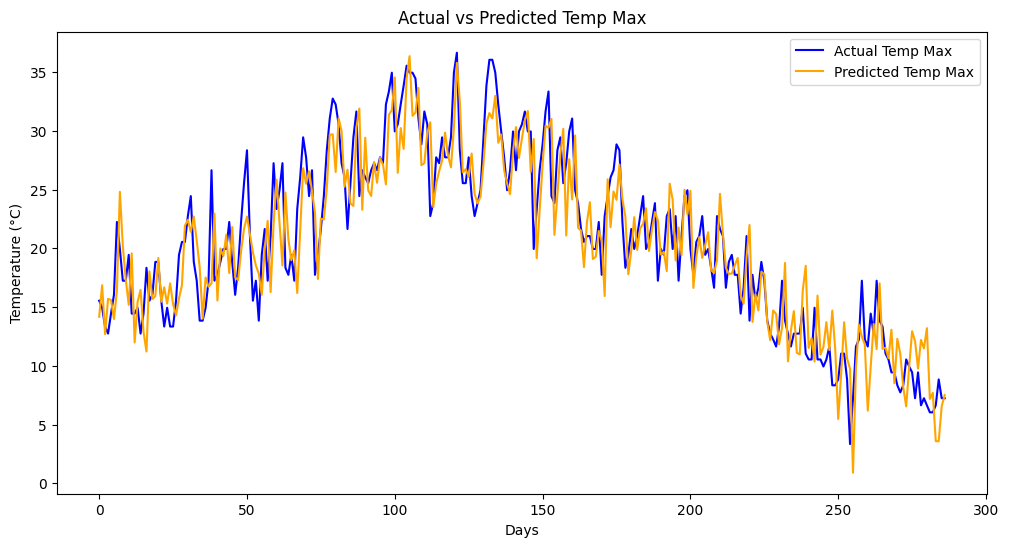

In [9]:
plt.figure(figsize=(12, 6))
plt.plot(y_test_rescaled, label='Actual Temp Max', color='blue')
plt.plot(y_pred_rescaled, label='Predicted Temp Max', color='orange')
plt.title('Actual vs Predicted Temp Max')
plt.xlabel('Days')
plt.ylabel('Temperature (°C)')
plt.legend()
plt.show()

In [10]:
model.save("rnn_weather_model.h5")
print("Model saved as rnn_weather_model.h5")

Model saved as rnn_weather_model.h5


In [11]:
lstm_model = Sequential([
    LSTM(64, activation="tanh", input_shape=(30,4)),
    Dense(32, activation="relu"),
    Dense(1)
])

lstm_model.compile(optimizer=Adam(learning_rate=0.001), loss="mean_squared_error")
lstm_model.summary()

c:\Users\vishe\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        17,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,777 (77.25 KB)

 Trainable params: 19,777 (77.25 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
from tensorflow.keras.layers import GRU

gru_model = Sequential([
    GRU(64, activation="tanh", input_shape=(30,4)),
    Dense(32, activation="relu"),
    Dense(1)
])

gru_model.compile(optimizer=Adam(learning_rate=0.001), loss="mean_squared_error")
gru_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 64)             │        13,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 15,553 (60.75 KB)

 Trainable params: 15,553 (60.75 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
history_lstm = lstm_model.fit(x_train, y_train, epochs=40, batch_size=16, validation_split=0.1, verbose = 1)
history_gru = gru_model.fit(x_train, y_train, epochs=40, batch_size=16, validation_split=0.1, verbose = 1)

y_pred_lstm = lstm_model.predict(x_test)
y_pred_gru = gru_model.predict(x_test)

y_pred_lstm_rescaled = y_pred_lstm/scaler.scale_[0] + scaler.min_[0]
y_pred_gru_rescaled = y_pred_gru/scaler.scale_[0] + scaler.min_[0]

Epoch 1/40
65/65 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0362 - val_loss: 0.0068
Epoch 2/40
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0090 - val_loss: 0.0069
Epoch 3/40
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0085 - val_loss: 0.0070
Epoch 4/40
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0081 - val_loss: 0.0063
Epoch 5/40
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0081 - val_loss: 0.0066
Epoch 6/40
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0080 - val_loss: 0.0064
Epoch 7/40
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0076 - val_loss: 0.0058
Epoch 8/40
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0073 - val_loss: 0.0056
Epoch 9/40
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0075 - val_loss: 0.0059
Epoch 10/40
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0070 - val_loss: 0.0058
Epoch 11/40
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0071 - val_loss: 0.0075
Epoch 12/40
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.0073 - val_lo

In [14]:
mae_lstm = mean_absolute_error(y_test_rescaled, y_pred_lstm_rescaled)
rmse_lstm = np.sqrt(mean_squared_error(y_test_rescaled, y_pred_lstm_rescaled))

mae_gru = mean_absolute_error(y_test_rescaled, y_pred_gru_rescaled)
rmse_gru = np.sqrt(mean_squared_error(y_test_rescaled, y_pred_gru_rescaled))

In [15]:
comparison_df = pd.DataFrame({
    "Metric": ["Mean Absolute Error", "Root Mean Squared Error"],
    "RNN": [mae, rmse],
    "LSTM": [mae_lstm, rmse_lstm],
    "GRU": [mae_gru, rmse_gru]
})

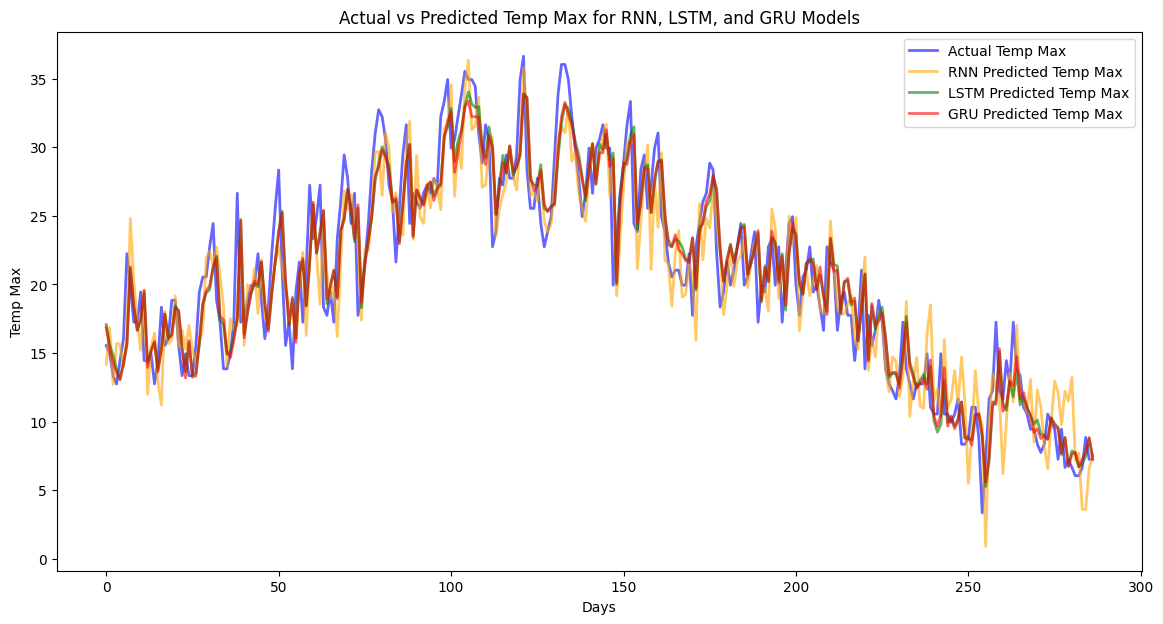

In [16]:
plt.figure(figsize=(14, 7))
plt.plot(y_test_rescaled, label='Actual Temp Max', color='blue', alpha=0.6, linewidth=2)
plt.plot(y_pred_rescaled, label='RNN Predicted Temp Max', color='orange', alpha=0.6, linewidth=2)
plt.plot(y_pred_lstm_rescaled, label='LSTM Predicted Temp Max', color='green', alpha=0.6, linewidth=2)
plt.plot(y_pred_gru_rescaled, label='GRU Predicted Temp Max', color='red', alpha=0.6, linewidth=2)
plt.title('Actual vs Predicted Temp Max for RNN, LSTM, and GRU Models')
plt.xlabel('Days')
plt.ylabel('Temp Max')
plt.legend()